# MLOps Assignment: Predictive Maintenance Classification
### Starter Notebook

**Domain:** Industrial IoT / Manufacturing
**Task:** Multi-class failure type prediction
**Tools:** Pandera, MLflow, Optuna, Evidently, SHAP

---

## Business Context

A heavy-equipment manufacturer runs 10,000+ machines on the shop floor.
Each machine continuously streams six sensor readings. When a machine fails,
production halts - at a cost of ₹8-15 lakh per hour of downtime.

Your job is to build a full MLOps pipeline that:
1. Validates incoming sensor data before it enters the pipeline (Pandera)
2. Trains and tracks a multi-class failure classifier (MLflow)
3. Tunes hyperparameters and registers the best model (Optuna + MLflow Registry)
4. Monitors the deployed model for distributional shift (Evidently)
5. Explains why the model predicts a specific failure type (SHAP)

**Files provided:**
- `data/train.csv`   - 6,993 labelled sensor readings (historical baseline)
- `data/current.csv` - 1,499 readings from the current stable production batch
- `data/stress.csv`  - 1,499 readings from a heavy-load production period

**Failure classes:**

| Code | Name | Description |
|------|------|-------------|
| 0 | No Failure | Machine operating normally |
| 1 | TWF | Tool Wear Failure |
| 2 | HDF | Heat Dissipation Failure |
| 3 | PWF | Power Failure |
| 4 | OSF | Overstrain Failure |

> Visual anchor: use the generated `reports/eda_distributions.png` early (Section 1.3) to ground your expectations before drift and SHAP interpretation.
> Stress-batch goal: diagnose *why* the model is stale under shifted operating conditions, not to force perfect predictions on `stress.csv`.
> **Submission:** Submit this notebook (`.ipynb`) with all cells executed.
> Do not change the section structure or remove any markdown cells.

## **1. Data Loading, Schema Validation & EDA**

### **1.1** Load the datasets

Load `train.csv`, `current.csv`, and `stress.csv` from the `data/` folder.
Print the shape of each and display the first 5 rows of the training set.


In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['DISABLE_PANDERA_IMPORT_WARNING'] = 'True'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the three datasets
train   = pd.read_csv('data/train.csv')
current = pd.read_csv('data/current.csv')
stress  = pd.read_csv('data/stress.csv')

# Print shapes
print(f'train  : {train.shape}')
print(f'current: {current.shape}')
print(f'stress : {stress.shape}')

CLASS_NAMES = {0: 'No Failure', 1: 'TWF', 2: 'HDF', 3: 'PWF', 4: 'OSF'}
OUTPUT_DIR = Path(".")
MODEL_DIR = OUTPUT_DIR / "model"
REPORTS_DIR = OUTPUT_DIR / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

train[:5]


train  : (6993, 7)
current: (1499, 7)
stress : (1499, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


### **1.2** Define and apply a Pandera schema

Define a `DataFrameSchema` enforcing the domain constraints below.
Validate `train` and `current` (must pass). Validate `stress` with `lazy=True`.

| Column | Type | Constraint |
|--------|------|------------|
| Type | str | one of L, M, H |
| Air temperature | float | [295.0, 305.0] K |
| Process temperature | float | [305.0, 315.0] K |
| Rotational speed | int64 | [1000, 2900] rpm |
| Torque | float | [3.0, 80.0] Nm |
| Tool wear | int64 | [0, 253] min |
| Failure_Type | int64 | 0, 1, 2, 3, 4 |


> `stress.csv` may still pass schema validation. That is fine: it is designed to be valid but drifted.
> Hint: valid data can still be statistically unusual. Before Section 3, compare the mean of `Rotational speed` in `current` vs `stress`.

In [2]:
import pandera as pa
from pandera import Column, DataFrameSchema, Check

# Define the schema
schema = DataFrameSchema({
    # fill in each column constraint
    'Type' : Column(str, Check.isin(['L', 'M', 'H'])),
    'Air temperature': Column(float, Check.between(295.0, 305.0)),
    'Process temperature': Column(float, Check.between(305.0, 315.0)),
    'Rotational speed': Column(int, Check.between(1000,2900)),
    'Torque': Column(float, Check.between(3, 80.0)),
    'Tool wear': Column(int, Check.between(0, 253)),
    'Failure_Type': Column(int, Check.isin([0, 1, 2, 3, 4])),
})

def fix_dtypes(df):
    df = df.copy()
    df['Rotational speed'] = df['Rotational speed'].astype('int64')
    df['Tool wear']        = df['Tool wear'].astype('int64')
    df['Failure_Type']     = df['Failure_Type'].astype('int64')
    return df

train   = fix_dtypes(train)
current = fix_dtypes(current)
stress  = fix_dtypes(stress)


try:
    schema.validate(current, lazy=True)
    print("Current dataset is valid.")
except pa.errors.SchemaError as e:
    print("Current dataset validation failed:")
    print(e.failure_cases)

# Validate train and current
try: 
    schema.validate(train, lazy=True)
    print("Train dataset is valid.")
except pa.errors.SchemaError as e:
    print("Train dataset validation failed:")
    print(e.failure_cases)

try:
    schema.validate(current, lazy=True)
    print("Current dataset is valid.")
except pa.errors.SchemaError as e:
    print("Current dataset validation failed:")
    print(e.failure_cases)

# Validate stress with lazy=True and print violation summary
try:
    schema.validate(stress, lazy=True)
    print("Stress dataset is valid.")
except pa.errors.SchemaError as e:
    print("Stress dataset validation failed:")
    violations = e.failure_cases
    summary = (violations.groupby(["column","check"], dropname=False).size().reset_index(name='violations_count'))
    print("Violation Summary:")
    print(summary.to_string(index=False))


Current dataset is valid.
Train dataset is valid.
Current dataset is valid.
Stress dataset is valid.


### **1.3** Exploratory Data Analysis

1. Print the class distribution of `Failure_Type`. Is it balanced?
2. Plot the distribution of `Torque` and `Tool wear` split by failure class (failures only).
3. Print the `Type` (L/M/H) distribution.


Class distribution:
              count  percentage
Failure_Type                   
No Failure     6762       96.70
TWF              30        0.43
HDF              76        1.09
PWF              56        0.80
OSF              69        0.99


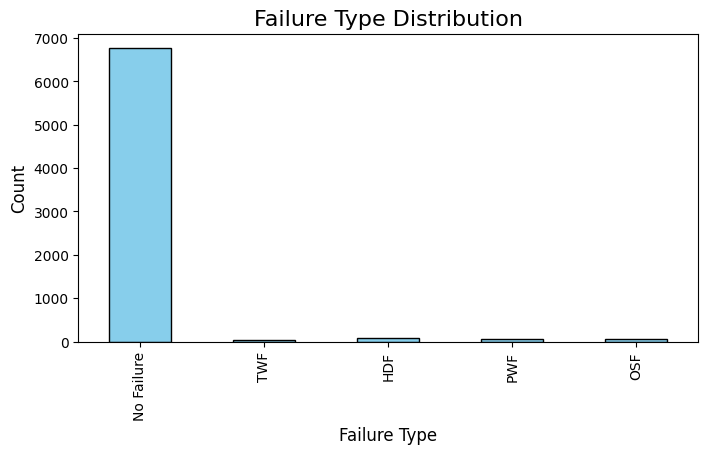

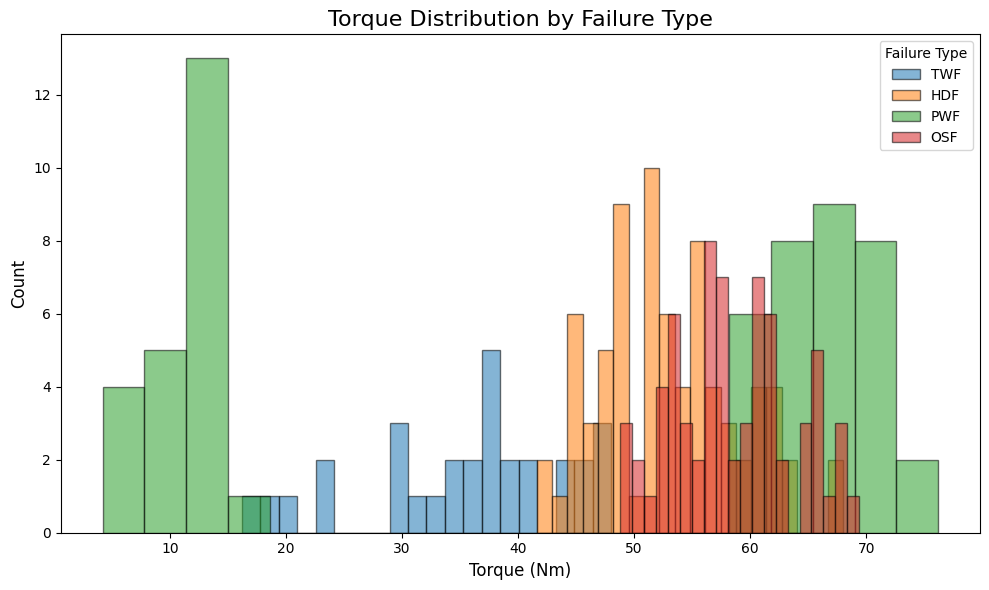

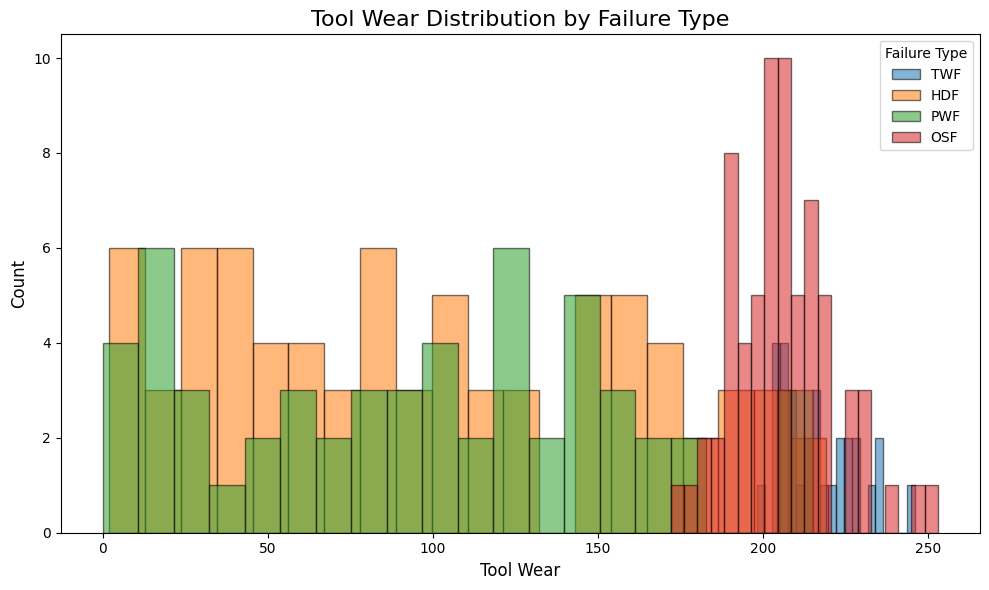

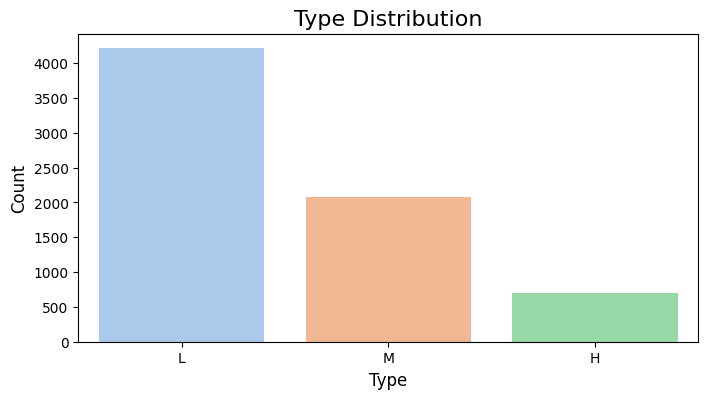

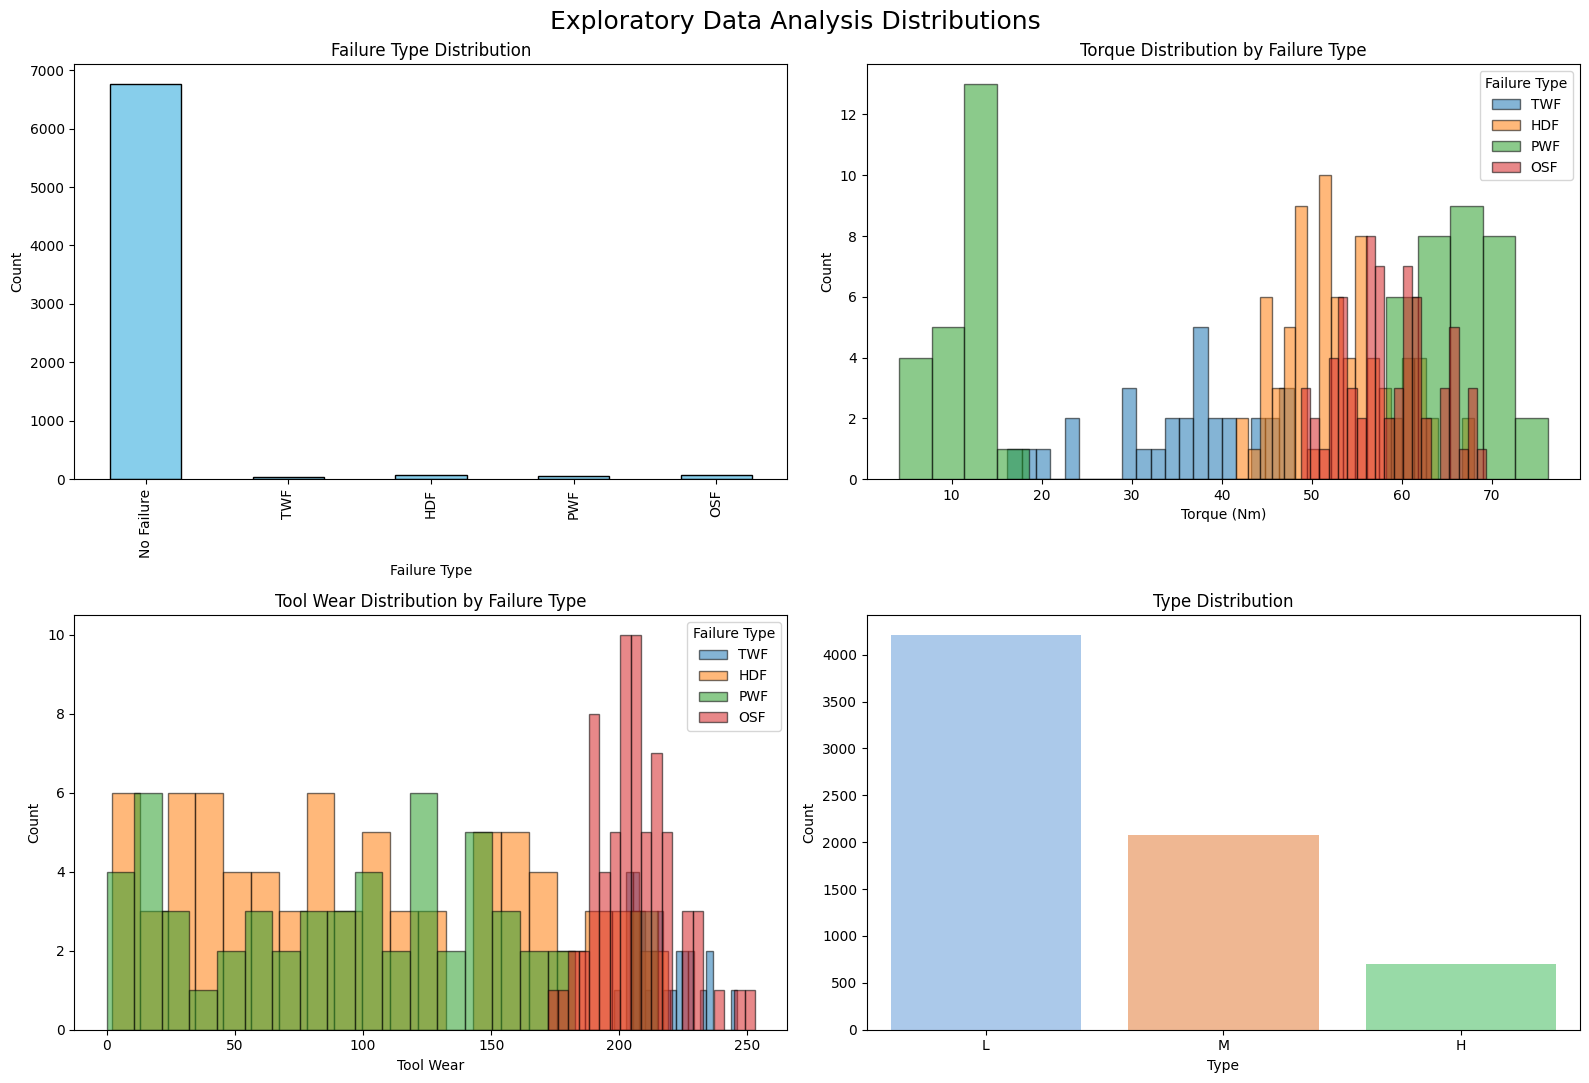

In [3]:
# Class distribution (print + bar chart)
print("Class distribution:")
summary = pd.DataFrame({
    "count": train['Failure_Type'].value_counts().sort_index(),
    "percentage": train['Failure_Type'].value_counts(normalize=True).sort_index() * 100
}).sort_index()

summary.index = summary.index.map(CLASS_NAMES)
print(summary.round(2))

counts = train["Failure_Type"].value_counts().reindex(CLASS_NAMES.keys(), fill_value=0)
ax = counts.rename(index=CLASS_NAMES).plot(kind='bar', figsize=(8, 4), color='skyblue', edgecolor='black')
ax.set_title('Failure Type Distribution', fontsize=16)
ax.set_xlabel('Failure Type', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
plt.show()

# Torque distribution by failure type (failures only)
plt.figure(figsize=(10, 6))
failure_data = train[train['Failure_Type'] != 0]

for class_code, class_name in CLASS_NAMES.items():
    torque_values = failure_data.loc[failure_data['Failure_Type'] == class_code, 'Torque']
    if not torque_values.empty:
        plt.hist(torque_values, bins=20, alpha=0.55, label=class_name, edgecolor='black')

plt.title('Torque Distribution by Failure Type', fontsize=16)
plt.xlabel('Torque (Nm)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(title='Failure Type')
plt.tight_layout()
plt.show()

# Tool wear distribution by failure type
plt.figure(figsize=(10, 6))
for class_code, class_name in CLASS_NAMES.items():
    tool_wear_values = failure_data.loc[failure_data['Failure_Type'] == class_code, 'Tool wear']
    if not tool_wear_values.empty:
        plt.hist(tool_wear_values, bins=20, alpha=0.55, label=class_name, edgecolor='black')

plt.title('Tool Wear Distribution by Failure Type', fontsize=16)
plt.xlabel('Tool Wear', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(title='Failure Type')
plt.tight_layout()
plt.show()

# Type distribution
plt.figure(figsize=(8, 4))
type_counts = train['Type'].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, palette='pastel')
plt.title('Type Distribution', fontsize=16)
plt.xlabel('Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

# Save a consolidated EDA figure beside the notebook
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

counts.rename(index=CLASS_NAMES).plot(
    kind='bar', ax=axes[0, 0], color='skyblue', edgecolor='black'
)
axes[0, 0].set_title('Failure Type Distribution')
axes[0, 0].set_xlabel('Failure Type')
axes[0, 0].set_ylabel('Count')

for class_code, class_name in CLASS_NAMES.items():
    torque_values = failure_data.loc[
        failure_data['Failure_Type'] == class_code, 'Torque'
    ]
    if not torque_values.empty:
        axes[0, 1].hist(
            torque_values, bins=20, alpha=0.55,
            label=class_name, edgecolor='black'
        )
axes[0, 1].set_title('Torque Distribution by Failure Type')
axes[0, 1].set_xlabel('Torque (Nm)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend(title='Failure Type')

for class_code, class_name in CLASS_NAMES.items():
    tool_wear_values = failure_data.loc[
        failure_data['Failure_Type'] == class_code, 'Tool wear'
    ]
    if not tool_wear_values.empty:
        axes[1, 0].hist(
            tool_wear_values, bins=20, alpha=0.55,
            label=class_name, edgecolor='black'
        )
axes[1, 0].set_title('Tool Wear Distribution by Failure Type')
axes[1, 0].set_xlabel('Tool Wear')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(title='Failure Type')

sns.barplot(
    x=type_counts.index, y=type_counts.values,
    ax=axes[1, 1], palette='pastel'
)
axes[1, 1].set_title('Type Distribution')
axes[1, 1].set_xlabel('Type')
axes[1, 1].set_ylabel('Count')

fig.suptitle('Exploratory Data Analysis Distributions', fontsize=18)
fig.tight_layout()
fig.savefig(REPORTS_DIR / 'eda_distributions.png', dpi=300, bbox_inches='tight')
plt.show()


### **1.4** Feature Engineering

Compute the following derived features for all three datasets:

**Mechanical power** (Watts):
$$P = \text{Torque} \times \frac{\text{Rotational speed} \times 2\pi}{60}$$

**Temperature differential**:
$$\Delta T = \text{Process temperature} - \text{Air temperature}$$

Print the mean of each new feature grouped by `Failure_Type`.


In [4]:
def engineer_features(df):
    df = df.copy()
    # TODO: Compute Power_W
    df['Power_W'] = (df['Torque'] * df['Rotational speed'] * 2 * np.pi) / 60
    df['Temp_diff'] = df['Process temperature'] - df['Air temperature']
    return df

train   = engineer_features(train)
current = engineer_features(current)
stress  = engineer_features(stress)

# Print grouped mean
grouped_mean = (
    train.groupby('Failure_Type')
         .mean(numeric_only=True)
         .rename(index=CLASS_NAMES)
 )
print("Grouped Mean by Failure Type:")
print(grouped_mean.round(2))


Grouped Mean by Failure Type:
              Air temperature  Process temperature  Rotational speed  Torque  \
Failure_Type                                                                   
No Failure             299.98               310.00           1540.33   39.65   
TWF                    300.30               310.26           1593.27   35.66   
HDF                    302.56               310.79           1335.62   53.00   
PWF                    300.16               309.99           1869.21   43.42   
OSF                    299.89               309.96           1342.96   58.54   

              Tool wear  Power_W  Temp_diff  
Failure_Type                                 
No Failure       106.40  6248.24      10.01  
TWF              216.20  5763.09       9.97  
HDF               97.68  7403.55       8.23  
PWF               95.54  6664.38       9.82  
OSF              206.23  8216.07      10.07  


## **2. Experiment Tracking & Model Selection**

### **2.1** Setup: features, split, SMOTE

Use the features below. Apply a stratified 80/20 train-val split (random_state=42).
Apply SMOTE to the training split only. Print the post-SMOTE class distribution.

```
FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
```

> In a markdown cell below the code, explain in 2–3 sentences why SMOTE is applied
> only to the training split and not the validation set.


In [5]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import joblib

# Encode Type column
le = LabelEncoder()
train['Type_enc']   = le.fit_transform(train['Type'])
current['Type_enc'] = le.transform(current['Type'])
stress['Type_enc']  = le.transform(stress['Type'])

# Persist the training-fitted encoder for consistent inference preprocessing
joblib.dump(le, MODEL_DIR / "label_encoder.pkl")

FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']

# Define X and y
X = train[FEATURES]
y = train['Failure_Type']

# Train-val split
X_train, X_val, y_train, y_val = train_test_split(X,y, test_size=0.20, random_state=42, stratify=y)

pre_smote_distribution = (
    pd.Series(y_train)
        .value_counts()
        .sort_index()
        .rename(index=CLASS_NAMES)
)

print("Pre-SMOTE class distribution:")
print(pre_smote_distribution)
print("-"*80)

# Apply SMOTE (k_neighbors=3, random_state=42)
smote = SMOTE(k_neighbors=3, random_state=42)
X_res , y_res = smote.fit_resample(X_train, y_train)
                                    
# Print post-SMOTE class distribution
post_smote_distribution = (
    pd.Series(y_res)
      .value_counts()
      .sort_index()
      .rename(index=CLASS_NAMES)
)

print("Post-SMOTE class distribution:")
print(post_smote_distribution)

Pre-SMOTE class distribution:
Failure_Type
No Failure    5409
TWF             24
HDF             61
PWF             45
OSF             55
Name: count, dtype: int64
--------------------------------------------------------------------------------
Post-SMOTE class distribution:
Failure_Type
No Failure    5409
TWF           5409
HDF           5409
PWF           5409
OSF           5409
Name: count, dtype: int64


*Your explanation here: why is SMOTE applied only on the training split?*

### **2.2** Train and log 4 models with MLflow

Train and evaluate:
- Logistic Regression
- Random Forest (n_estimators=100)
- XGBoost (n_estimators=100)
- LightGBM (n_estimators=100)

MLflow experiment name: `PredMaint_ModelSelection`

For each run log: `model` (param), `macro_f1`, `weighted_f1`, `accuracy` (metrics),
and per-class F1 for all 5 classes. Print a comparison table. Pick the best model by macro F1.


In [6]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier




db_path = OUTPUT_DIR / "mlflow" / "mlflow.db"
db_path.parent.mkdir(parents=True, exist_ok=True)
tracking_uri = f"sqlite:///{db_path}"

print("MLflow database:", db_path)

mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("PredMaint_ModelSelection")

# Create or retrieve the experiment

CLASS_LIST = [0, 1, 2, 3, 4]
results = {}

models_to_run = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, random_state=42,
                                  class_weight='balanced'))
    ]),
    'RandomForest':       RandomForestClassifier(n_estimators=100, random_state=42,
                                                  class_weight='balanced'),
    'XGBoost':            XGBClassifier(n_estimators=100, random_state=42,
                                         eval_metric='mlogloss', verbosity=0),
    'LightGBM':           LGBMClassifier(n_estimators=100, random_state=42,
                                          class_weight='balanced', verbose=-1),
}

# For each model:
#   - Start an MLflow run
#   - Fit on X_res, y_res
#   - Predict on X_val
#   - Compute and log macro_f1, weighted_f1, accuracy, per-class F1
#   - Log the model artefact (use input_example=X_val.iloc[:5])

for model_name, model in models_to_run.items():
    with mlflow.start_run(run_name=model_name):
        model.fit(X_res, y_res)
        y_pred = model.predict(X_val)

        macro_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average='macro',
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average='weighted',
            zero_division=0
        )

        accuracy = accuracy_score(y_val, y_pred)

        per_class_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average=None,
            zero_division=0
        )

        mlflow.log_param("model", model_name)
        mlflow.log_metrics({
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "accuracy": accuracy
        })


        # Log F1 for every fail class
        class_metrics = {
            f"f1_{CLASS_NAMES[class_code].lower().replace(' ','_')}" : float(score)
            for class_code, score in zip(CLASS_LIST, per_class_f1)
        }

        mlflow.log_metrics(class_metrics)

        mlflow.sklearn.log_model(
            model,
            "model",
            input_example=X_val.iloc[:5]
        )

        results[model_name] = {
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "accuracy": accuracy,
            **class_metrics
        }

comparison_table = (
    pd.DataFrame(results)
    .T
    .sort_values("macro_f1",ascending=False)
)

# Print comparison table
display(comparison_table.round(4))

# Identify best model by macro F1
best_model_name = comparison_table["macro_f1"].idxmax()
print(f"Best Model by Macro F1 : {best_model_name}")

MLflow database: mlflow/mlflow.db


2026/11/06 06:37:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/06 06:37:35 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

,macro_f1,weighted_f1,accuracy,f1_no_failure,f1_twf,f1_hdf,f1_pwf,f1_osf
XGBoost,0.7481,0.9851,0.9843,0.9922,0.1333,0.9655,0.8800,0.7692
RandomForest,0.7355,0.9855,0.9850,0.9926,0.0000,0.9286,0.9565,0.8000
LightGBM,0.7296,0.9851,0.9843,0.9922,0.0000,0.9655,0.8333,0.8571
LogisticRegression,0.5312,0.9328,0.9042,0.9483,0.1449,0.4545,0.4583,0.6500


Best Model by Macro F1 : XGBoost


### **2.3** Optuna tuning + MLflow Model Registry

Run an Optuna study (30 trials, `TPESampler(seed=42)`) tuning XGBoost hyperparameters.
Optimise for `macro_f1` on `X_val`.

MLflow experiment: `PredMaint_Optuna`

Register the best model as `PredMaint_XGBoost` and promote it to the `production` alias.
Print the improvement in macro F1 over the baseline XGBoost.


In [7]:
import optuna
import joblib
import mlflow.xgboost
from mlflow.tracking import MlflowClient


optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_experiment('PredMaint_Optuna')

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight':  trial.suggest_float('min_child_weight', 1.0, 10.0),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma':             trial.suggest_float('gamma', 0.0, 2.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'random_state': 42, 'eval_metric': 'mlogloss', 'verbosity': 0,
    }
    # Train XGBoost model, return macro_f1 on X_val
    model = XGBClassifier(**params)
    model.fit(X_res, y_res)
    y_pred = model.predict(X_val)

    return f1_score(
        y_val,y_pred,
        labels=CLASS_LIST,
        average="macro",
        zero_division=0
    )
    
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=42))

# Run study.optimize
study.optimize(objective, n_trials=30)

print("Best Macro F1: ", study.best_value)
print("Best parametres:", study.best_params)


# Train final best model
best_params = {
    **study.best_params,
    "random_state": 42,
    "eval_metric": "mlogloss",
    "verbosity": 0
}

best_model = XGBClassifier(**best_params)
best_model.fit(X_res,y_res)

tuned_prediction = best_model.predict(X_val)
tuned_macro_f1 = f1_score(
    y_val,
    tuned_prediction,
    labels=CLASS_LIST,
    average="macro",
    zero_division=0
)

# Log to MLflow, register as 'PredMaint_XGBoost', promote to production alias
with mlflow.start_run(run_name="XGBoost_Optuna_Best") as run:
    mlflow.log_params(best_params)
    mlflow.log_metric("macro_f1", tuned_macro_f1)
    mlflow.xgboost.log_model(
        best_model,
        "model",
        input_example=X_val.iloc[:5]
    )
    model_uri = f"runs/{run.info.run_id}/model"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name="PredMaint_XGBoost"
)

client = MlflowClient()
client.set_registered_model_alias(
    name="PredMaint_XGBoost",
    alias="Production",
    version=registered_model.version
)

# Save with joblib.dump
joblib.dump(best_model, MODEL_DIR / "best_model.pkl")
print("Tuned macro F1:", tuned_macro_f1)
print("Registerd model version: ", registered_model.version)


2026/11/06 06:37:49 INFO mlflow.tracking.fluent: Experiment with name 'PredMaint_Optuna' does not exist. Creating a new experiment.


Best Macro F1:  0.7573043267624548
Best parametres: {'n_estimators': 192, 'max_depth': 8, 'learning_rate': 0.07294854281727606, 'min_child_weight': 1.098902703193942, 'subsample': 0.7242150291507374, 'colsample_bytree': 0.8759347993734068, 'gamma': 0.538341987519164, 'reg_alpha': 0.9710904766545863, 'reg_lambda': 2.13802078884986e-05}
Tuned macro F1: 0.7573043267624548
Registerd model version:  1


Successfully registered model 'PredMaint_XGBoost'.
Created version '1' of model 'PredMaint_XGBoost'.


## **3. Drift Detection & Monitoring**

> Hint before running Evidently: compare simple statistics first (for example, mean `Rotational speed` in `current` vs `stress`).
> Reminder: passing Pandera only means values are valid; it does **not** mean the batch is in-distribution.
> Section objective: identify why the deployed model is stale on stress conditions.

### **3.1** Evidently — current batch

Reference: `train[FEAT_COLS]` | Current: `current[FEAT_COLS]`

```
FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']
```

Run `DataDriftPreset`. Save HTML to `reports/drift_current.html`.
Report: drift detected? How many features drifted?


In [8]:
from evidently.legacy.report import Report
from evidently.legacy.metric_preset import DataDriftPreset

FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']

# Run Evidently on current batch, save drift_current.html, print summary

print("Rotational speed mean:")
print("---"*50)
print("Train: ", train['Rotational speed'].mean())
print("Current: ", current['Rotational speed'].mean())
print("Stress: ", stress['Rotational speed'].mean())

current_report = Report(metrics=[DataDriftPreset()])
current_report.run(
    reference_data=train[FEAT_COLS],
    current_data=current[FEAT_COLS]
)


current_report.save_html(str(REPORTS_DIR / "drift_current.html"))
current_result = current_report.as_dict()

current_drift = next(
    metric['result']
    for metric in current_result['metrics']
    if "dataset_drift" in metric['result']
)

print("-"*50)
print("Current Batch Drift Detected:", current_drift['dataset_drift'])
print("Number of drifted features:", current_drift["number_of_drifted_columns"])

Rotational speed mean:
------------------------------------------------------------------------------------------------------------------------------------------------------
Train:  1539.017589017589
Current:  1530.165443629086
Stress:  1497.0747164776517
--------------------------------------------------
Current Batch Drift Detected: False
Number of drifted features: 0


### **3.2** Evidently - stress batch

Repeat for `stress.csv`. Use `ColumnDriftMetric` for individual feature scores.
Save as `reports/drift_stress.html`.
Print a table: feature | drift detected | Wasserstein score | ref mean | current mean | delta.

Focus question: this section is about diagnosing *staleness risk* (what shifted and why), not "making stress predictions look good."

In [9]:
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

# Run Evidently on stress batch with per-column metrics
stress_metrics = [DatasetDriftMetric()]
stress_metrics.extend(
    ColumnDriftMetric(column_name=feature)
    for feature in FEAT_COLS
)

stress_report = Report(metrics=stress_metrics)
stress_report.run(
    reference_data=train[FEAT_COLS],
    current_data=stress[FEAT_COLS]
)

#Save drift_stress.html
stress_report.save_html(str(REPORTS_DIR / "drift_stress.html"))
stress_result = stress_report.as_dict()

dataset_drift = next(
    metric["result"]
    for metric in stress_result["metrics"]
    if "dataset_drift" in metric["result"]
)

print("Stress batch drift detected: ", dataset_drift['dataset_drift'])
print("Number of drifted features:", dataset_drift["number_of_drifted_columns"])

print("-"*80)

stress_rows = []
for metric in stress_result["metrics"]:
    result = metric["result"]
    feature = result.get("column_name")

    if feature in FEAT_COLS:
        ref_mean = train[feature].mean()
        stress_mean = stress[feature].mean()

        stress_rows.append({
            "feature": feature,
            "drift_detected": result.get("drift_detected"),
            "wasserstein_score": result.get("drift_score"),
            "ref_mean": ref_mean,
            "current_mean": stress_mean,
            "delta": stress_mean - ref_mean
        })

# Print per-column drift table
stress_table = pd.DataFrame(stress_rows)

print("Stress feature drift:")
display(stress_table.round(4))

Stress batch drift detected:  True
Number of drifted features: 3
--------------------------------------------------------------------------------
Stress feature drift:


,feature,drift_detected,wasserstein_score,ref_mean,current_mean,delta
0,Air temperature,False,0.0344,300.0116,300.0538,0.0422
1,Process temperature,False,0.0377,310.0049,310.0086,0.0037
2,Rotational speed,True,0.2354,1539.0176,1497.0747,-41.9429
3,Torque,True,0.4739,39.9958,44.7241,4.7283
4,Tool wear,True,0.6455,107.6791,148.8699,41.1908


### **3.3** Retraining decision

Answer the following in a markdown cell:
1. Which features drifted in the stress batch?
2. Cross-referencing with your SHAP results (Section 4) ? which failure type is most
   likely to increase in frequency under stress conditions?
3. Should the model be retrained? Justify with evidence from Sections 3.1, 3.2, and 4.

Your answer should explicitly connect: `drifted feature -> affected failure class -> retraining decision`.

**Your answer here:**

1. Features that drifted: ... "Rotational Speed, Torque, Tool wear"
2. Most likely failure type to increase: ... OSF (overstrain Failure) is most likely to increase under stress conditions. Torque and Tool wear are the 2 strongest features for OSF. Both increase substantially in the stress dataset.
3. Retraining recommendation: Investigate and prepare for retraining: three of the five monitored features drifted, with higher torque and tool wear and lower rotational speed. This suggests changed operating conditions and potentially higher OSF risk, but drift alone does not prove poorer predictions. Compare stress-period predictions with actual failure labels, check macro F1 and per-class recall, and retrain if performance has deteriorated.


## **4. Explainability & Insights**

> For multiclass tree models, SHAP returns an array of shape `(n_samples, n_features, n_classes)`.
>
> **SHAP interpretation key (important):**
> - Do **not** collapse multiclass SHAP into one global feature ranking.
> - Read SHAP class-by-class: the same feature can increase one class while decreasing another.
> - Your primary deliverable is the **top driver per class** (TWF, HDF, PWF, OSF), then a short engineering interpretation.

### **4.1** SHAP analysis per failure class

Load `model/best_model.pkl`. Use `shap.TreeExplainer` on `train[FEATURES]`.
Plot mean |SHAP| bar charts for TWF, HDF, PWF, OSF (4 subplots). Save as `reports/shap_per_class.png`.
Print the top driver for each failure class.

Interpretation rule: report one top feature per class from `reports/shap_per_class.png`; avoid a single cross-class "global winner."

TWF: top driver = Tool wear (mean |SHAP| = 3.0004)
HDF: top driver = Temp_diff (mean |SHAP| = 2.7093)
PWF: top driver = Power_W (mean |SHAP| = 3.4636)
OSF: top driver = Torque (mean |SHAP| = 1.8490)


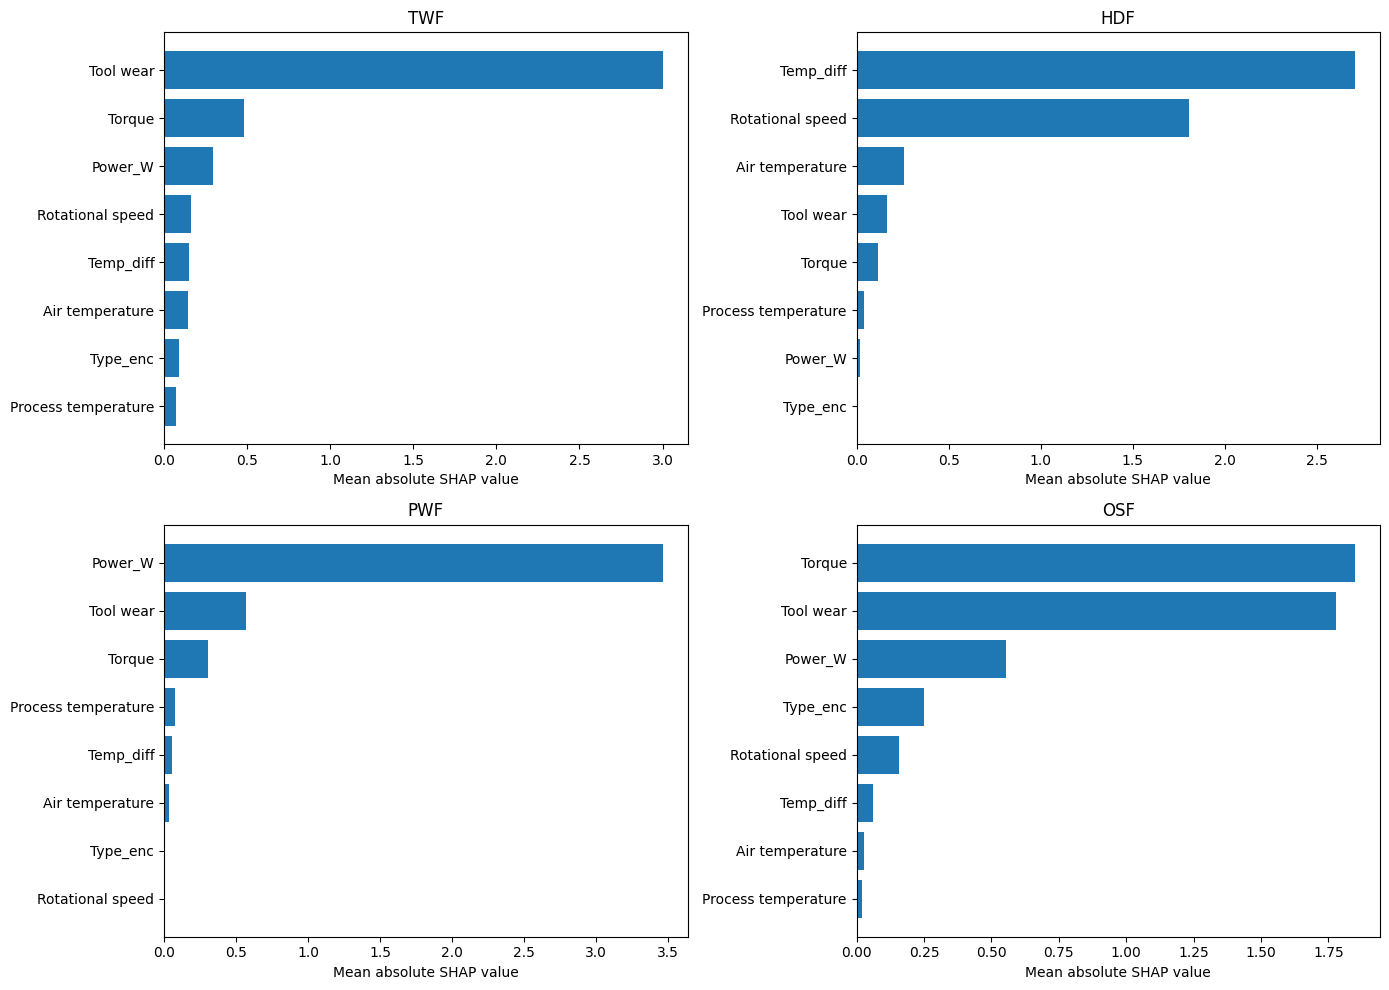

In [10]:
import joblib
import shap

best_model = joblib.load(MODEL_DIR / 'best_model.pkl')
# Match the features and column order used during model training.
X_shap = train[list(best_model.feature_names_in_)]

# TreeExplainer explains predictions from your tree model. 
explainer = shap.TreeExplainer(best_model)
# SHAP assigns each feature a contribution relative to a baseline prediction.
shap_values = explainer(X_shap).values # # rows, features, classes

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, class_code in zip(axes.flat, [1, 2, 3, 4]):
    class_index = list(best_model.classes_).index(class_code)
    # Average magnitudes so positive and negative contributions do not cancel.
    importance = np.abs(shap_values[:, :, class_index]).mean(axis=0)
    order = np.argsort(importance)
    ax.barh(X_shap.columns.to_numpy()[order], importance[order])
    ax.set_title(CLASS_NAMES[class_code])
    ax.set_xlabel("Mean absolute SHAP value")

    top_index = np.argmax(importance)
    print(
        f"{CLASS_NAMES[class_code]}: "
        f"top driver = {X_shap.columns[top_index]} "
        f"(mean |SHAP| = {importance[top_index]:.4f})"
    )

plt.tight_layout()
plt.savefig(REPORTS_DIR / "shap_per_class.png", dpi=300, bbox_inches="tight")
plt.show()


### **4.2** Engineering insight

Answer in this markdown cell:

1. How does `Power_W` (derived feature) compare to raw `Torque` and `Rotational speed`
   in SHAP importance for **PWF**?
2. How does `Temp_diff` rank for **HDF** vs other failure types? 
3. In 2-3 sentences, describe the physical mechanism behind each failure type based on SHAP.

Suggested structure for your actionable recommendation (used again in Section 5.1.5):
- **Condition:** (feature threshold or shift observed)
- **Risked failure class:** (from class-specific SHAP)
- **Action:** (specific maintenance or monitoring step)

**Your answer here:**

1. Power_W for PWF: ...  `Power_W` contributes more to PWF than `Torque` and `Rotational speed` with mean SHAP around 3.46.
2. Temp_diff for HDF: ... `Temp_diff` stands top with a mean SHAP value of 2.70,  than other failure classes. It ranks lower for other failure types - 5th for TWF & PWF and 6 for OSF.
3. Physical mechanisms: ... 
   - TWF (Tool Wear Failure) shows dominance with tool degradation. Some operations aspects like torque also conributes to the failure.
   - HDF (Heat Dissipation Failure) Temp_diff and Rotational speed dominate the model's predictions - and these look like thermal conditions and operating speed. 
   - PWF (Power Failure) Power_W dominates the model prediction and can infer that if power falls outside the acceptable operating range.
   - OSF (Overstrain Failure): Torque and Tool wear are strongest features - consistent with mechanical strain acting on a worn tool. 


## **5. Conclusions**

### **5.1** Key findings

Write a structured conclusion:

1. Which model won and why - reference macro F1 numbers.
2. Why accuracy is misleading here - operational cost implication.
3. TWF has F1 = 0.0 even after SMOTE + Optuna. Root cause and fix.
   - Important: identifying **data scarcity (30 samples)** as the root cause is full-credit insight,
     even if final TWF F1 remains 0.0.
4. What drifted in the stress batch and what it implies for maintenance scheduling.
5. One actionable recommendation for the engineering team based on SHAP.

## Conclusions

**1. Model selection:**
XGBoost won with the highest validation macro F1 of 0.7481, outperforming Random Forest (0.7355) and LightGBM (0.7296) and Logistic Regression (0.5312).
Macro F1 was the criterion because it weights all feature classes equally despite class imbalance. 

XGBoost achieve the strongest overall balance, including a non zero TWF detection where the other tree models scored 0. However its TWF F1 score reminaed low (0.1333) and its modest lead over Random Forest would need a repeated validation to establish robustness.

**2. Accuracy vs Macro F1:**
Accuracy is misleading because the "No Failure" classes are dominant and can cover up poor detection of rare failures. Operationally, such missed failures can cause costly unplaned downtime and equipment damage, while false alarms create unecessary maintainance cost. 

Model evaluation should therefore include macro f1, per class recall, and confusion matrix with particular attention to the cost of missed failures. 

**3. The TWF problem:**
State this as a data engineering limitation first (rare class with only 30 real samples),
then propose what data should be collected next.

- TWF is a rare class with only 24 real samples (before SMOTE as infered from the notebook) - leaving inssuficient coverage of the conditions leading to tool wear failure. SMOTE cannot add new real-world failure patterns and Optuna cannot cover for this data limitation.

- In the Next Data Collection : Collect more confirmed TWF events with accurate failure timestamps, tool age, replacement history and sensor readings before failure (all regular features). Include comparable healthy and worn but not failed tools across equipment types and operating loads so the model can distinguish normal wear from impending failure.

**4. Drift and maintenance schedule:**
- The drift was evident in 3 of the 5 features tracked - namely Rotational Speed, Torque, Tool Wear. This implies that Higher Torque and greater tool wear increased the mechanical strain. They are also the strongest SHAP drivers for OSF. 
- Prioritize tool condition checks, replacement of heavily worn tools and review operating loads. Use Equipment specific wear and load limits to set inspection triggers - drift alone does not eastablish an exact replacement interval.

**5. Actionable recommendation:**
Use this format: Condition -> Risked failure class -> Action.

- Condition - Elevated torque combined with high tool wear are the 2 strongest SHAP drivers for OSF (Overstrained Failures)
- Risked failure class - OSF
- Action - Flag affected equipment for an earlier tool inspection, replace tools exceeding approved wear limits, and reduce operating load until inspection is finished. 